In [1]:

# Import libraries
import pandas as pd
from pathlib import Path

# Locate the dataset
data_path = Path("../data/raw/training_data.csv")

# Load the CSV file
df = pd.read_csv(data_path)

# Display the first 5 rows
print("Dataset loaded successfully!")
display(df.head())


Dataset loaded successfully!


,Patient ID,Recording locations:,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Systolic murmur pitch,Systolic murmur quality,Diastolic murmur timing,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Outcome,Campaign,Additional ID
0,2530,AV+PV+TV+MV,Child,Female,98.0,15.9,False,Absent,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
1,9979,AV+PV+TV+MV,Child,Female,103.0,13.1,False,Present,AV+MV+PV+TV,TV,...,High,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
2,9983,AV+PV+TV+MV,Child,Male,115.0,19.1,False,Unknown,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
3,13918,AV+PV+TV+MV,Child,Male,98.0,15.9,False,Present,TV,TV,...,Low,Blowing,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN
4,14241,AV+PV+TV+MV,Child,Male,87.0,11.2,False,Present,AV+MV+PV+TV,PV,...,Low,Harsh,NaN,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN


In [2]:

# Explore the dataset

# Check the number of patients and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Count patients by murmur status
print("\nHeart murmur distribution:")
print(df["Murmur"].value_counts(dropna=False))


Dataset shape: (942, 23)

Column names:
['Patient ID', 'Recording locations:', 'Age', 'Sex', 'Height', 'Weight', 'Pregnancy status', 'Murmur', 'Murmur locations', 'Most audible location', 'Systolic murmur timing', 'Systolic murmur shape', 'Systolic murmur grading', 'Systolic murmur pitch', 'Systolic murmur quality', 'Diastolic murmur timing', 'Diastolic murmur shape', 'Diastolic murmur grading', 'Diastolic murmur pitch', 'Diastolic murmur quality', 'Outcome', 'Campaign', 'Additional ID']

Missing values:
Patient ID                    0
Recording locations:          0
Age                          74
Sex                           0
Height                      116
Weight                      105
Pregnancy status              0
Murmur                        0
Murmur locations            763
Most audible location       763
Systolic murmur timing      764
Systolic murmur shape       764
Systolic murmur grading     764
Systolic murmur pitch       764
Systolic murmur quality     764
Diastolic 

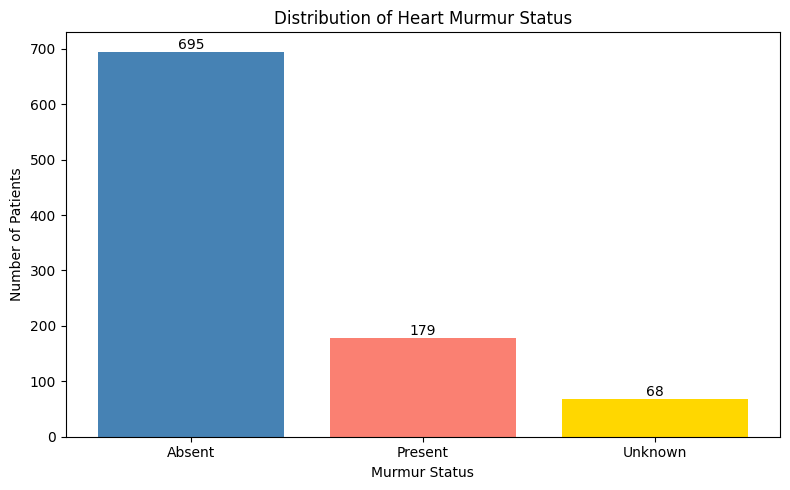

In [3]:

# Visualize heart murmur distribution

import matplotlib.pyplot as plt

# Count patients in each murmur category
murmur_counts = df["Murmur"].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    murmur_counts.index,
    murmur_counts.values,
    color=["steelblue", "salmon", "gold"]
)

# Add labels and title
plt.title("Distribution of Heart Murmur Status")
plt.xlabel("Murmur Status")
plt.ylabel("Number of Patients")

# Display counts above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(int(bar.get_height())),
        ha="center"
    )

plt.tight_layout()
plt.show()


Heart Murmur Distribution by Age Group:


Murmur,Absent,Present,Unknown
Age,,,
Adolescent,53,16,3
Child,495,132,37
Infant,76,25,25
Neonate,4,1,1


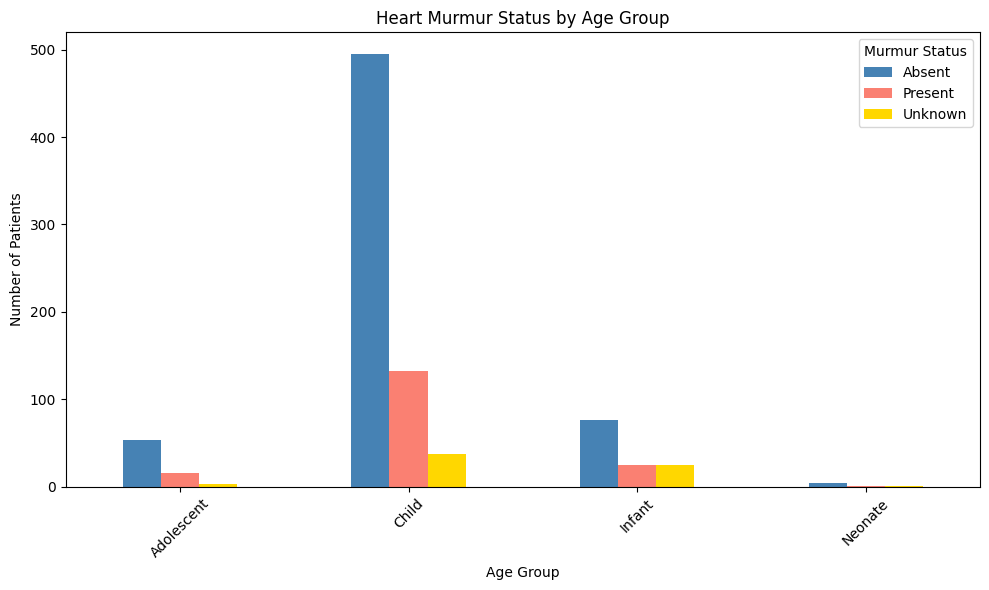

In [4]:

# Explore heart murmur status by age group

import pandas as pd
import matplotlib.pyplot as plt

# Create a table comparing age groups and murmur status
age_murmur = pd.crosstab(df["Age"], df["Murmur"])

# Display the table
print("Heart Murmur Distribution by Age Group:")
display(age_murmur)

# Plot the distribution
age_murmur.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "salmon", "gold"]
)

plt.title("Heart Murmur Status by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.legend(title="Murmur Status")
plt.tight_layout()
plt.show()


Heart Murmur Distribution by Sex:


Murmur,Absent,Present,Unknown
Sex,,,
Female,355,92,39
Male,340,87,29



Percentage Distribution by Sex:


Murmur,Absent,Present,Unknown
Sex,,,
Female,73.05,18.93,8.02
Male,74.56,19.08,6.36


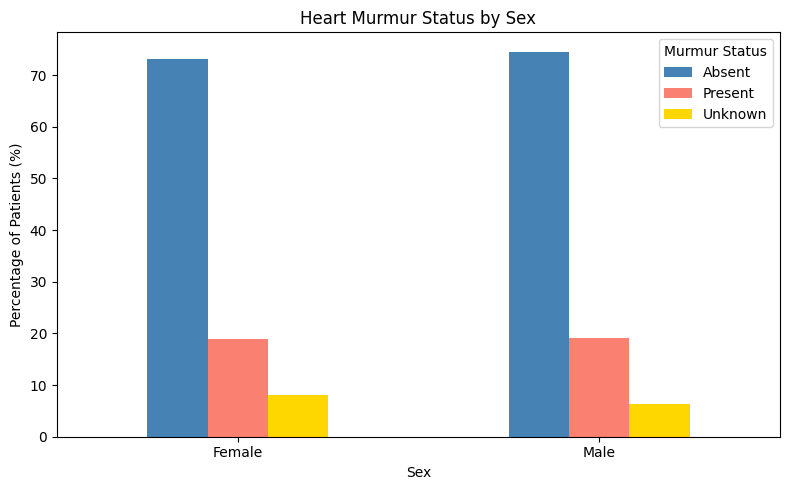

In [5]:

# Explore heart murmur status by sex

import pandas as pd
import matplotlib.pyplot as plt

# Count patients by sex and murmur status
sex_murmur = pd.crosstab(df["Sex"], df["Murmur"])

# Display the counts
print("Heart Murmur Distribution by Sex:")
display(sex_murmur)

# Calculate percentages within each sex
sex_percent = sex_murmur.div(sex_murmur.sum(axis=1), axis=0) * 100

print("\nPercentage Distribution by Sex:")
display(sex_percent.round(2))

# Plot percentage distribution
sex_percent.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "salmon", "gold"]
)

plt.title("Heart Murmur Status by Sex")
plt.xlabel("Sex")
plt.ylabel("Percentage of Patients (%)")
plt.xticks(rotation=0)
plt.legend(title="Murmur Status")
plt.tight_layout()
plt.show()


Visualize missing values

Missing Values (%):


Diastolic murmur grading    99.47
Diastolic murmur pitch      99.47
Diastolic murmur timing     99.47
Diastolic murmur quality    99.47
Diastolic murmur shape      99.47
Additional ID               85.14
Systolic murmur shape       81.10
Systolic murmur grading     81.10
Systolic murmur pitch       81.10
Systolic murmur timing      81.10
Systolic murmur quality     81.10
Murmur locations            81.00
Most audible location       81.00
Height                      12.31
Weight                      11.15
Age                          7.86
dtype: float64

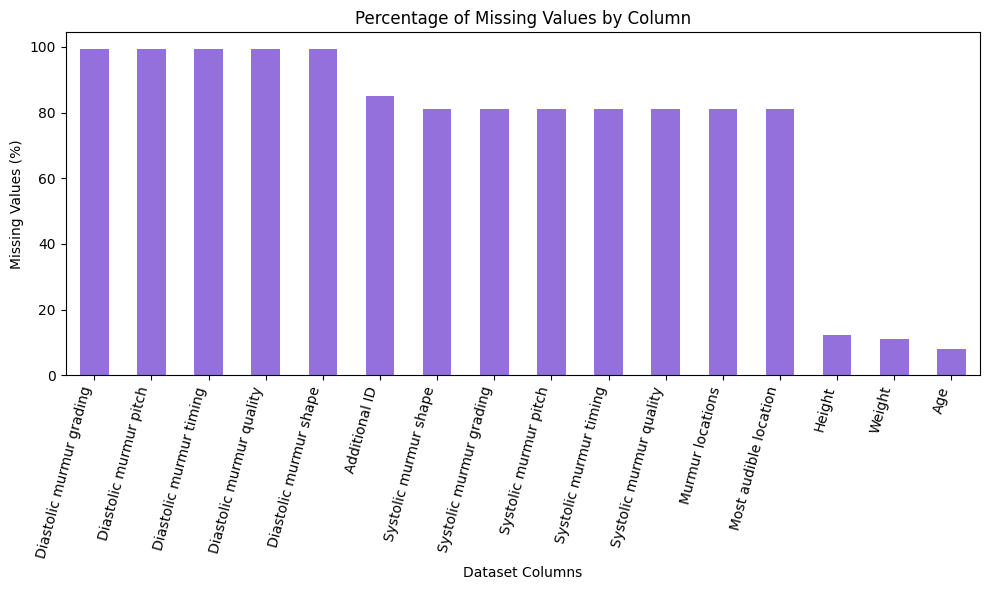

In [6]:

# Visualize missing values in the dataset

import matplotlib.pyplot as plt

# Calculate percentage of missing values
missing_percent = (df.isnull().sum() / len(df)) * 100

# Keep columns that contain missing values
missing_percent = missing_percent[missing_percent > 0]

# Sort from highest to lowest
missing_percent = missing_percent.sort_values(ascending=False)

# Display missing value percentages
print("Missing Values (%):")
display(missing_percent.round(2))

# Create bar chart
plt.figure(figsize=(10, 6))

missing_percent.plot(
    kind="bar",
    color="mediumpurple"
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Dataset Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


Saving the graphs

In [7]:

# Save EDA visualizations for our final report

from pathlib import Path
import matplotlib.pyplot as plt

# Create the figures folder if necessary
figures_path = Path("../reports/figures")
figures_path.mkdir(parents=True, exist_ok=True)

# 1. Murmur distribution
ax = df["Murmur"].value_counts().plot(
    kind="bar", color="steelblue", figsize=(8, 5)
)
ax.set_title("Distribution of Heart Murmur Status")
ax.set_xlabel("Murmur Status")
ax.set_ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures_path / "murmur_distribution.png", dpi=300)
plt.close()

# 2. Murmur status by age group
age_murmur = pd.crosstab(df["Age"], df["Murmur"])
age_murmur.plot(kind="bar", figsize=(9, 5))
plt.title("Heart Murmur Status by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.savefig(figures_path / "murmur_by_age.png", dpi=300)
plt.close()

# 3. Murmur status by sex (percentage)
sex_murmur = pd.crosstab(df["Sex"], df["Murmur"])
sex_percent = sex_murmur.div(
    sex_murmur.sum(axis=1), axis=0
) * 100

sex_percent.plot(kind="bar", figsize=(8, 5))
plt.title("Heart Murmur Status by Sex")
plt.xlabel("Sex")
plt.ylabel("Percentage of Patients (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures_path / "murmur_by_sex.png", dpi=300)
plt.close()

# 4. Missing values
missing_percent = df.isnull().mean() * 100
missing_percent = missing_percent[missing_percent > 0]
missing_percent.sort_values(ascending=False).plot(
    kind="bar", color="mediumpurple", figsize=(11, 5)
)
plt.title("Percentage of Missing Values by Column")
plt.ylabel("Missing Values (%)")
plt.tight_layout()
plt.savefig(figures_path / "missing_values.png", dpi=300)
plt.close()

print("All four graphs saved successfully!")


All four graphs saved successfully!



## Exploratory Data Analysis Summary

The CirCor heart sound dataset contains 942 patient records
and 23 columns with demographic and clinical information.

### Key Findings

1. **Murmur Distribution:** Out of 942 patients,
   695 were labeled Absent, 179 Present, and 68 Unknown.
   This shows that the dataset is imbalanced, with
   significantly more patients without murmurs.

2. **Age Distribution:** Children make up the largest
   age group in the dataset. The number of patients
   varies across age groups, so percentages should
   also be considered when comparing murmur occurrence.

3. **Sex Distribution:** Murmur-present labels were
   recorded for 18.93% of female patients and 19.08%
   of male patients. The percentages are very similar.

4. **Missing Values:** Several murmur-specific columns
   contain substantial missing data, especially
   diastolic and systolic murmur characteristics.
   These missing values may be related to whether
   a murmur was documented.

### Implications for Machine Learning

- Class imbalance should be considered during
  model training and evaluation.
- Precision, recall, and F1-score will be important
  alongside accuracy.
- Patients with Unknown murmur labels should be
  handled separately during supervised training.
- Audio recordings will be needed to extract features
  for heart murmur detection.

### Conclusion

This exploratory analysis provides an initial
understanding of the patient metadata, label
distribution, and missing values. The next stage
will focus on preprocessing heart sound recordings
and preparing data for machine learning models.
